# NLP Lab Assignment: Hindi Part-of-Speech (POS) Tagging
## Comparative Study: Naive Bayes vs. Hidden Markov Models (HMM)

### Overview
This notebook implements and comparatively evaluates Part-of-Speech (POS) tagging on the **Hindi POS Dataset** using four distinct modeling and decoding strategies:
1. **Naive Bayes POS Classifier** with 5 contextual and morphological features and Laplace smoothing.
2. **HMM - Forward Viterbi Decoding** (Standard Dynamic Programming Viterbi recovering the globally optimal sequence).
3. **HMM - Backward Viterbi Decoding** (Backward Dynamic Programming with forward pointer tracking, mathematically consistent with the Viterbi objective).
4. **HMM - Forward-Backward Posterior Decoding** (Posterior marginal decoding maximizing expected token-level accuracy via log-sum-exp forward-backward passes).

All model probabilities are estimated **strictly from the training dataset** (`hindi-train-pos.txt`). Models are evaluated on both the **Development set** (`hindi-dev-pos.txt`) and **Test set** (`hindi-test-pos.txt`).

---
### Notebook Structure
- **Section 1:** Environment Setup & Library Imports
- **Section 2:** Data Preprocessing & Exploratory Analysis
- **Section 3:** Naive Bayes POS Classifier Implementation & Training
- **Section 4:** Hidden Markov Model (HMM) Parameter Estimation
- **Section 5:** Decoding Algorithms (Forward Viterbi, Backward Viterbi, Forward-Backward)
- **Section 6:** Comprehensive Model Evaluation (Dev & Test Sets)
- **Section 7:** Visualizations (Performance Comparisons & Confusion Matrices)
- **Section 8:** Detailed Comparison, Analysis & Discussion


## 1. Environment Setup & Library Imports

We import standard Python libraries for file handling, numerical operations, data structures, and evaluation metrics. In accordance with assignment instructions, all model probability estimations, feature extractors, and decoding algorithms are **implemented from scratch**. `scikit-learn` is utilized solely for metric computation (Precision, Recall, F1-score, Confusion Matrix).


In [1]:
import os
import math
import time
import random
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# Set random seeds for strict reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Matplotlib & Seaborn styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = True

print("✓ All libraries imported successfully.")
print(f"✓ Random seed set to {SEED}.")


✓ All libraries imported successfully.
✓ Random seed set to 42.


## 2. Data Preprocessing & Exploratory Analysis

### Dataset Format
The dataset files are formatted as tab-separated lines containing a word and its corresponding POS tag (`<word>\t<tag>`). Sentences are delineated by empty blank lines. 

Key preprocessing considerations:
1. **Unicode Safety:** Files are read using `utf-8` encoding to preserve Devanagari script characters without corruption.
2. **Boundary Handling:** Blank lines mark sentence transitions. We handle multi-space/tab delimiters and strip invisible whitespace.
3. **Data Integrity:** Only the training split is used for vocabulary and parameter estimation to avoid any data leakage into validation or testing.


In [2]:
def load_pos_dataset(filepath):
    """
    Reads a POS-tagged text file and parses it into sentences.
    Each sentence is represented as a list of (word, tag) tuples.
    """
    sentences = []
    current_sentence = []
    malformed_count = 0
    
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line_str = line.strip()
            if not line_str:
                if current_sentence:
                    sentences.append(current_sentence)
                    current_sentence = []
                continue
            
            # Split on tab first; fallback to whitespace
            parts = line_str.split('\t')
            if len(parts) != 2:
                parts = line_str.split()
            
            if len(parts) == 2:
                word, tag = parts[0], parts[1]
                current_sentence.append((word, tag))
            else:
                malformed_count += 1
                
    if current_sentence:
        sentences.append(current_sentence)
        
    return sentences, malformed_count

# Paths to the three dataset splits in the current directory
train_file = "hindi-train-pos.txt"
dev_file = "hindi-dev-pos.txt"
test_file = "hindi-test-pos.txt"

train_sents, train_mal = load_pos_dataset(train_file)
dev_sents, dev_mal = load_pos_dataset(dev_file)
test_sents, test_mal = load_pos_dataset(test_file)

# Dataset Statistics
train_tokens = [w for s in train_sents for w, t in s]
dev_tokens = [w for s in dev_sents for w, t in s]
test_tokens = [w for s in test_sents for w, t in s]

train_vocab = set(train_tokens)
dev_vocab = set(dev_tokens)
test_vocab = set(test_tokens)

train_tags = sorted(list({t for s in train_sents for w, t in s}))
tag2idx = {t: i for i, t in enumerate(train_tags)}
idx2tag = {i: t for i, t in enumerate(train_tags)}

dev_oov = [w for w in dev_tokens if w not in train_vocab]
test_oov = [w for w in test_tokens if w not in train_vocab]

print("=" * 65)
print("              HINDI POS DATASET SUMMARY STATISTICS")
print("=" * 65)
stats_df = pd.DataFrame({
    "Split": ["Training (train)", "Development (dev)", "Testing (test)"],
    "Sentences": [len(train_sents), len(dev_sents), len(test_sents)],
    "Total Tokens": [len(train_tokens), len(dev_tokens), len(test_tokens)],
    "Unique Words": [len(train_vocab), len(dev_vocab), len(test_vocab)],
    "OOV Tokens": [0, len(dev_oov), len(test_oov)],
    "OOV Rate (%)": [0.0, (len(dev_oov) / len(dev_tokens)) * 100, (len(test_oov) / len(test_tokens)) * 100],
    "Malformed Lines": [train_mal, dev_mal, test_mal]
})
print(stats_df.to_string(index=False))
print("=" * 65)
print(f"Total Unique POS Tags ({len(train_tags)}): {train_tags}\n")

print("--- Sample Parsed Training Sentence ---")
for word, tag in train_sents[0]:
    print(f"  {word:<15} -> {tag}")


              HINDI POS DATASET SUMMARY STATISTICS
            Split  Sentences  Total Tokens  Unique Words  OOV Tokens  OOV Rate (%)  Malformed Lines
 Training (train)      15087        325710         18279           0      0.000000                0
Development (dev)       1866         40762          5814        1707      4.187724                0
   Testing (test)       1910         41415          5873        1899      4.585295                0
Total Unique POS Tags (24): ['CC_CCD', 'CC_CCS', 'DM_DMD', 'JJ', 'N_NN', 'N_NNP', 'N_NST', 'PR_PRF', 'PR_PRL', 'PR_PRP', 'PR_PRQ', 'PSP', 'QT_QTC', 'QT_QTF', 'QT_QTO', 'RB', 'RD_PUNC', 'RD_SYM', 'RP_INJ', 'RP_INTF', 'RP_NEG', 'RP_RPD', 'V_VAUX', 'V_VM']

--- Sample Parsed Training Sentence ---
  यह              -> DM_DMD
  एशिया           -> N_NNP
  की              -> PSP
  सबसे            -> RP_INTF
  बड़ी             -> JJ
  मस्जिदों        -> N_NN
  में             -> PSP
  से              -> PSP
  एक              -> QT_QTC
  है             

## 3. Naive Bayes POS Classifier

### Feature Extraction
For each word $w_i$ at position $i$ in a sentence $(w_1, w_2, \dots, w_N)$, we extract five features:
1. **$f_0$ (Word Length):** Binary feature: `MORE` if $\text{length}(w_i) > 4$, else `LESS`.
2. **$f_1$ (Current Word):** $w_i$.
3. **$f_2$ (Previous Word):** $w_{i-1}$ (or `<START_WORD>` if $i=0$).
4. **$f_3$ (Next Word):** $w_{i+1}$ (or `<END_WORD>` if $i=N-1$).
5. **$f_4$ (Previous Tag):** 
   - During **training**, we use the true gold tag $t_{i-1}$ (or `<START_TAG>` if $i=0$).
   - During **testing/inference**, to prevent label leakage, we use the **previously predicted tag** $\hat{t}_{i-1}$ (or `<START_TAG>` if $i=0$). Prediction proceeds sequentially from left to right.

### Mathematical Formulation
Under the Naive Bayes assumption, the conditional probability of tag $t \in T$ given feature vector $\mathbf{f} = (f_0, f_1, f_2, f_3, f_4)$ is proportional to:
$$P(t \mid \mathbf{f}) \propto P(t) \prod_{j=0}^{4} P(f_j \mid t)$$

In log-space to prevent underflow:
$$\log P(t \mid \mathbf{f}) = \log P(t) + \sum_{j=0}^{4} \log P(f_j \mid t)$$

### Laplace (Additive) Smoothing
- **Prior Probability:**
  $$P(t) = \frac{\text{Count}(t) + \alpha}{N_{\text{tokens}} + \alpha |T|}$$
- **Conditional Feature Probability:**
  $$P(f_j = v \mid t) = \frac{\text{Count}(f_j = v, t) + \alpha}{\text{Count}(t) + \alpha (|V_j| + 1)}$$
  where $|V_j|$ is the number of distinct observed values for feature $j$ in training data, and the $+1$ accounts for unseen feature values encountered at test time.


In [3]:
class NaiveBayesPOSTagger:
    """
    Naive Bayes Part-of-Speech Tagger using 5 lexical and contextual features:
    1. Word length: 'MORE' (>4) or 'LESS' (<=4)
    2. Actual current word
    3. Previous word
    4. Next word
    5. Previous tag (Gold during training, predicted during inference)
    """
    def __init__(self, alpha=1.0):
        self.alpha = alpha
        self.tag_counts = Counter()
        self.total_tokens = 0
        self.tags = []
        
        # Feature counts per tag: feature_index -> tag -> Counter(value)
        self.feat_counts = [defaultdict(Counter) for _ in range(5)]
        self.feat_vocab = [set() for _ in range(5)]
        
        self.log_priors = {}
        self.default_log_prob = [{} for _ in range(5)]
        self.log_feat_probs = [defaultdict(dict) for _ in range(5)]

    def extract_features(self, words, i, prev_tag):
        """Extracts the 5 specified features for the token at index i."""
        w = words[i]
        f0 = 'MORE' if len(w) > 4 else 'LESS'
        f1 = w
        f2 = words[i - 1] if i > 0 else '<START_WORD>'
        f3 = words[i + 1] if i + 1 < len(words) else '<END_WORD>'
        f4 = prev_tag
        return (f0, f1, f2, f3, f4)

    def train(self, sentences):
        """Estimates priors and conditional probabilities from training sentences."""
        for s in sentences:
            words = [w for w, t in s]
            gold_tags = [t for w, t in s]
            for i in range(len(s)):
                t = gold_tags[i]
                prev_tag = gold_tags[i - 1] if i > 0 else '<START_TAG>'
                feats = self.extract_features(words, i, prev_tag)
                
                self.tag_counts[t] += 1
                self.total_tokens += 1
                
                for f_idx, f_val in enumerate(feats):
                    self.feat_counts[f_idx][t][f_val] += 1
                    self.feat_vocab[f_idx].add(f_val)

        self.tags = sorted(list(self.tag_counts.keys()))
        num_tags = len(self.tags)
        
        # Compute log priors
        for t in self.tags:
            cnt = self.tag_counts[t]
            self.log_priors[t] = math.log((cnt + self.alpha) / (self.total_tokens + self.alpha * num_tags))

        # Compute log conditional feature probabilities with Laplace smoothing
        for j in range(5):
            v_size = len(self.feat_vocab[j]) + 1  # +1 for unseen test values
            for t in self.tags:
                cnt = self.tag_counts[t]
                denom = cnt + self.alpha * v_size
                log_denom = math.log(denom)
                # Unseen feature probability: alpha / denom
                self.default_log_prob[j][t] = math.log(self.alpha) - log_denom
                # Observed feature probabilities
                for val, val_cnt in self.feat_counts[j][t].items():
                    self.log_feat_probs[j][t][val] = math.log(val_cnt + self.alpha) - log_denom

    def predict_sentence(self, words):
        """
        Predicts tags sequentially for a single sentence.
        Uses the previously predicted tag as the context feature for the next token.
        """
        pred_tags = []
        for i in range(len(words)):
            prev_t = pred_tags[-1] if pred_tags else '<START_TAG>'
            feats = self.extract_features(words, i, prev_t)
            
            best_tag = None
            best_score = -float('inf')
            
            for t in self.tags:
                score = self.log_priors[t]
                for j in range(5):
                    val = feats[j]
                    score += self.log_feat_probs[j][t].get(val, self.default_log_prob[j][t])
                    
                if score > best_score:
                    best_score = score
                    best_tag = t
                    
            pred_tags.append(best_tag)
        return pred_tags

print("Training Naive Bayes POS Tagger on training set...")
start_time = time.time()
nb_tagger = NaiveBayesPOSTagger(alpha=1.0)
nb_tagger.train(train_sents)
print(f"✓ Naive Bayes trained in {time.time() - start_time:.2f} seconds.")


Training Naive Bayes POS Tagger on training set...
✓ Naive Bayes trained in 0.54 seconds.


## 4. Hidden Markov Model (HMM) - Parameter Estimation

An HMM models the joint distribution of word sequences $\mathbf{w} = (w_1, \dots, w_N)$ and POS tag sequences $\mathbf{t} = (t_1, \dots, t_N)$:
$$P(\mathbf{w}, \mathbf{t}) = P(t_1) P(w_1 \mid t_1) \prod_{k=2}^{N} P(t_k \mid t_{k-1}) P(w_k \mid t_k)$$

### Probability Estimations with Laplace Smoothing
1. **Initial State Probabilities $\pi(i) = P(t_1 = i)$:**
   $$\pi(i) = \frac{\text{Count}(t_1 = i) + \alpha}{N_{\text{sentences}} + \alpha |T|}$$
2. **Transition Probabilities $A(j \mid i) = P(t_k = j \mid t_{k-1} = i)$:**
   $$A(j \mid i) = \frac{\text{Count}(t_{k-1} = i, t_k = j) + \alpha}{\text{Count}(t = i) + \alpha |T|}$$
3. **Emission Probabilities $B(w \mid i) = P(w_k = w \mid t_k = i)$:**
   $$B(w \mid i) = \frac{\text{Count}(t_k = i, w_k = w) + \alpha}{\text{Count}(t = i) + \alpha (|V| + 1)}$$
   For an unseen out-of-vocabulary word $w \notin V$:
   $$B(w \mid i) = \frac{\alpha}{\text{Count}(t = i) + \alpha (|V| + 1)}$$

All calculations are performed directly in log-space to ensure numerical stability and avoid floating-point underflow.


In [4]:
class HMMPOSTagger:
    """
    Hidden Markov Model (HMM) for Part-of-Speech Tagging.
    Estimates initial, transition, and emission log-probabilities with Laplace smoothing.
    Supports Forward Viterbi, Backward Viterbi, and Forward-Backward posterior decoding.
    """
    def __init__(self, alpha=1.0):
        self.alpha = alpha
        self.tags = []
        self.tag2idx = {}
        self.idx2tag = {}
        self.num_tags = 0
        self.vocab = set()
        
        # Log parameter matrices/lookups
        self.log_initial = None          # Shape: (num_tags,)
        self.log_transition = None       # Shape: (num_tags, num_tags) [from_tag, to_tag]
        self.log_emission = {}           # word -> np.ndarray of shape (num_tags,)
        self.default_log_emission = None # Shape: (num_tags,) for OOV words

    def train(self, sentences):
        """Estimates HMM parameters from training sentences."""
        self.tags = sorted(list({t for s in sentences for w, t in s}))
        self.num_tags = len(self.tags)
        self.tag2idx = {t: i for i, t in enumerate(self.tags)}
        self.idx2tag = {i: t for i, t in enumerate(self.tags)}
        
        init_counts = np.zeros(self.num_tags, dtype=np.float64)
        trans_counts = np.zeros((self.num_tags, self.num_tags), dtype=np.float64)
        tag_counts = np.zeros(self.num_tags, dtype=np.float64)
        word_tag_counts = defaultdict(lambda: np.zeros(self.num_tags, dtype=np.float64))
        
        num_sentences = len(sentences)
        for s in sentences:
            if not s:
                continue
            first_tag_idx = self.tag2idx[s[0][1]]
            init_counts[first_tag_idx] += 1
            
            for i, (w, t) in enumerate(s):
                t_idx = self.tag2idx[t]
                tag_counts[t_idx] += 1
                word_tag_counts[w][t_idx] += 1
                self.vocab.add(w)
                if i > 0:
                    prev_t_idx = self.tag2idx[s[i - 1][1]]
                    trans_counts[prev_t_idx, t_idx] += 1

        # 1. Initial log probabilities
        self.log_initial = np.log((init_counts + self.alpha) / (num_sentences + self.alpha * self.num_tags))
        
        # 2. Transition log probabilities: P(to | from)
        trans_denom = tag_counts[:, None] + self.alpha * self.num_tags
        self.log_transition = np.log((trans_counts + self.alpha) / trans_denom)
        
        # 3. Emission log probabilities: P(w | t)
        v_size = len(self.vocab) + 1
        emiss_denom = tag_counts + self.alpha * v_size
        self.default_log_emission = np.log(self.alpha / emiss_denom)
        for w, counts in word_tag_counts.items():
            self.log_emission[w] = np.log((counts + self.alpha) / emiss_denom)

    def get_emission_log_probs(self, word):
        """Returns the array of log P(word | tag) for all tags."""
        return self.log_emission.get(word, self.default_log_emission)

print("Estimating HMM parameters from training set...")
start_time = time.time()
hmm_tagger = HMMPOSTagger(alpha=1.0)
hmm_tagger.train(train_sents)
print(f"✓ HMM parameters estimated in {time.time() - start_time:.2f} seconds.")
print(f"  - Initial state distribution: shape {hmm_tagger.log_initial.shape}")
print(f"  - Transition matrix: shape {hmm_tagger.log_transition.shape}")
print(f"  - Emission vocabulary entries: {len(hmm_tagger.log_emission)}")


Estimating HMM parameters from training set...
✓ HMM parameters estimated in 0.23 seconds.
  - Initial state distribution: shape (24,)
  - Transition matrix: shape (24, 24)
  - Emission vocabulary entries: 18279


## 5. Decoding Algorithms

We implement three distinct decoding strategies for the HMM:

---
### 5A. Standard Forward Viterbi
The Viterbi algorithm finds the globally most probable state sequence:
$$\mathbf{y}^* = \arg\max_{\mathbf{y}} P(\mathbf{y}, \mathbf{w})$$

**Forward Recurrence:**
- **Base case ($t = 0$):**
  $$v_0(j) = \log \pi(j) + \log B(w_0 \mid j)$$
- **Recursive step ($t = 1 \dots N-1$):**
  $$v_t(j) = \max_{i} \left[ v_{t-1}(i) + \log A(j \mid i) \right] + \log B(w_t \mid j)$$
  $$bp_t(j) = \arg\max_{i} \left[ v_{t-1}(i) + \log A(j \mid i) \right]$$
- **Termination & Backtracking:**
  $$y_{N-1}^* = \arg\max_j v_{N-1}(j)$$
  $$y_{t-1}^* = bp_t(y_t^*) \quad \text{for } t = N-1 \dots 1$$

---
### 5B. Backward Viterbi
Backward Viterbi performs dynamic programming in reverse, starting from the end of the sentence ($t = N-1$) back to the beginning ($t = 0$), yet optimizes the exact same joint probability objective.

**Backward Recurrence:**
- Let $\beta^{\text{vit}}_t(i)$ denote the maximum probability of emitting the future observation suffix $w_{t+1} \dots w_{N-1}$ and following the optimal future tag suffix given state $i$ at position $t$:
- **Base case ($t = N-1$):**
  $$\beta^{\text{vit}}_{N-1}(i) = 0 \quad (\log 1.0)$$
- **Recursive step ($t = N-2$ down to $0$):**
  $$\beta^{\text{vit}}_t(i) = \max_j \left[ \log A(j \mid i) + \log B(w_{t+1} \mid j) + \beta^{\text{vit}}_{t+1}(j) \right]$$
  $$fp_t(i) = \arg\max_j \left[ \log A(j \mid i) + \log B(w_{t+1} \mid j) + \beta^{\text{vit}}_{t+1}(j) \right]$$
- **Termination & Forward Tracking:**
  At position $t = 0$, combine initial probability, first emission, and future potential:
  $$\text{Score}_0(i) = \log \pi(i) + \log B(w_0 \mid i) + \beta^{\text{vit}}_0(i)$$
  $$y_0^* = \arg\max_i \text{Score}_0(i)$$
  Follow forward pointers forward in time:
  $$y_{t+1}^* = fp_t(y_t^*) \quad \text{for } t = 0 \dots N-2$$

---
### 5C. Forward-Backward Posterior Decoding
Unlike Viterbi (which finds the single most probable entire path), **Posterior Decoding** finds the tag that maximizes the posterior probability independently at each individual position:
$$\hat{y}_t = \arg\max_i P(y_t = i \mid \mathbf{w}) = \arg\max_i \frac{\alpha_t(i) \beta_t(i)}{\sum_j \alpha_t(j) \beta_t(j)}$$

**Formulation via Log-Sum-Exp:**
1. **Forward Pass ($\log \alpha$):**
   $$\log \alpha_0(i) = \log \pi(i) + \log B(w_0 \mid i)$$
   $$\log \alpha_t(j) = \text{logsumexp}_i \left( \log \alpha_{t-1}(i) + \log A(j \mid i) \right) + \log B(w_t \mid j)$$
2. **Backward Pass ($\log \beta$):**
   $$\log \beta_{N-1}(i) = 0$$
   $$\log \beta_t(i) = \text{logsumexp}_j \left( \log A(j \mid i) + \log B(w_{t+1} \mid j) + \log \beta_{t+1}(j) \right)$$
3. **Posterior Selection:**
   $$\hat{y}_t = \arg\max_i \left( \log \alpha_t(i) + \log \beta_t(i) \right)$$
   *(The denominator normalizer is constant across all tags at step $t$ and does not affect $\arg\max$.)*


In [5]:
def viterbi_forward(hmm, words):
    """Standard Forward Viterbi Decoding."""
    N = len(words)
    if N == 0:
        return []
        
    viterbi = np.zeros((N, hmm.num_tags), dtype=np.float64)
    backpointer = np.zeros((N, hmm.num_tags), dtype=np.int32)
    
    # Base case: t = 0
    viterbi[0] = hmm.log_initial + hmm.get_emission_log_probs(words[0])
    
    # Forward recursion: t = 1 ... N-1
    for t in range(1, N):
        emiss = hmm.get_emission_log_probs(words[t])
        # viterbi[t-1][:, None]: from_tag (num_tags, 1)
        # hmm.log_transition: (from_tag, to_tag)
        scores = viterbi[t - 1][:, None] + hmm.log_transition
        backpointer[t] = np.argmax(scores, axis=0)
        viterbi[t] = np.max(scores, axis=0) + emiss
        
    # Backtrack
    best_path = [0] * N
    best_path[-1] = int(np.argmax(viterbi[-1]))
    for t in range(N - 1, 0, -1):
        best_path[t - 1] = int(backpointer[t, best_path[t]])
        
    return [hmm.idx2tag[i] for i in best_path]

def viterbi_backward(hmm, words):
    """Backward Viterbi Decoding with forward pointer tracking."""
    N = len(words)
    if N == 0:
        return []
    if N == 1:
        scores = hmm.log_initial + hmm.get_emission_log_probs(words[0])
        return [hmm.idx2tag[int(np.argmax(scores))]]
        
    beta_vit = np.zeros((N, hmm.num_tags), dtype=np.float64)
    forward_pointer = np.zeros((N, hmm.num_tags), dtype=np.int32)
    
    # Backward recursion: t = N-2 down to 0
    for t in range(N - 2, -1, -1):
        next_emiss = hmm.get_emission_log_probs(words[t + 1])
        # Transition from i to j: log_transition[i, j] + next_emiss[j] + beta_vit[t+1, j]
        scores = hmm.log_transition + next_emiss[None, :] + beta_vit[t + 1][None, :]
        forward_pointer[t] = np.argmax(scores, axis=1)
        beta_vit[t] = np.max(scores, axis=1)
        
    # Start position: t = 0
    start_scores = hmm.log_initial + hmm.get_emission_log_probs(words[0]) + beta_vit[0]
    best_path = [0] * N
    best_path[0] = int(np.argmax(start_scores))
    
    # Track forward
    for t in range(0, N - 1):
        best_path[t + 1] = int(forward_pointer[t, best_path[t]])
        
    return [hmm.idx2tag[i] for i in best_path]

def forward_backward_decode(hmm, words):
    """Forward-Backward Algorithm with Posterior Marginal Decoding."""
    N = len(words)
    if N == 0:
        return []
        
    log_alpha = np.zeros((N, hmm.num_tags), dtype=np.float64)
    log_beta = np.zeros((N, hmm.num_tags), dtype=np.float64)
    
    # Forward Pass: log alpha
    log_alpha[0] = hmm.log_initial + hmm.get_emission_log_probs(words[0])
    for t in range(1, N):
        emiss = hmm.get_emission_log_probs(words[t])
        m = log_alpha[t - 1][:, None] + hmm.log_transition
        max_m = np.max(m, axis=0)
        log_sum = max_m + np.log(np.sum(np.exp(m - max_m[None, :]), axis=0))
        log_alpha[t] = log_sum + emiss
        
    # Backward Pass: log beta
    for t in range(N - 2, -1, -1):
        next_emiss = hmm.get_emission_log_probs(words[t + 1])
        m = hmm.log_transition + next_emiss[None, :] + log_beta[t + 1][None, :]
        max_m = np.max(m, axis=1)
        log_sum = max_m + np.log(np.sum(np.exp(m - max_m[:, None]), axis=1))
        log_beta[t] = log_sum
        
    # Posterior decoding: argmax_i (log alpha_t(i) + log beta_t(i))
    posterior_scores = log_alpha + log_beta
    best_path = np.argmax(posterior_scores, axis=1)
    return [hmm.idx2tag[int(i)] for i in best_path]

# Bind methods to HMMPOSTagger instance
hmm_tagger.viterbi_forward = lambda words: viterbi_forward(hmm_tagger, words)
hmm_tagger.viterbi_backward = lambda words: viterbi_backward(hmm_tagger, words)
hmm_tagger.forward_backward_decode = lambda words: forward_backward_decode(hmm_tagger, words)

print("✓ All three HMM decoders successfully bound and ready for inference.")


✓ All three HMM decoders successfully bound and ready for inference.


## 6. Comprehensive Model Evaluation

We evaluate all four models on both the **Development Set** (1,866 sentences, 40,762 tokens) and the **Test Set** (1,910 sentences, 41,415 tokens):
1. **Naive Bayes POS Classifier**
2. **HMM - Forward Viterbi**
3. **HMM - Backward Viterbi**
4. **HMM - Forward-Backward Posterior Decoding**

For each model and split, we compute:
- Token-level Overall Accuracy
- Macro-averaged and Weighted-averaged Precision, Recall, and F1-score
- Detailed per-tag classification reports
- Confusion matrices across the 24 POS tags


In [6]:
def run_evaluation(sentences, split_name):
    """Evaluates all 4 models on a given split and computes comprehensive metrics."""
    print(f"\nEvaluating models on {split_name} ({len(sentences)} sentences)...")
    gold_tokens = []
    nb_preds = []
    fwd_preds = []
    bwd_preds = []
    fb_preds = []
    
    t0 = time.time()
    for s in sentences:
        words = [w for w, t in s]
        golds = [t for w, t in s]
        gold_tokens.extend(golds)
        
        nb_preds.extend(nb_tagger.predict_sentence(words))
        fwd_preds.extend(hmm_tagger.viterbi_forward(words))
        bwd_preds.extend(hmm_tagger.viterbi_backward(words))
        fb_preds.extend(hmm_tagger.forward_backward_decode(words))
        
    print(f"✓ Inference completed in {time.time() - t0:.2f} seconds.")
    
    models = {
        "Naive Bayes": nb_preds,
        "Forward Viterbi": fwd_preds,
        "Backward Viterbi": bwd_preds,
        "Forward-Backward": fb_preds
    }
    
    metrics_summary = []
    reports = {}
    conf_matrices = {}
    
    for name, preds in models.items():
        acc = accuracy_score(gold_tokens, preds)
        p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
            gold_tokens, preds, average='macro', zero_division=0
        )
        p_weighted, r_weighted, f1_weighted, _ = precision_recall_fscore_support(
            gold_tokens, preds, average='weighted', zero_division=0
        )
        
        metrics_summary.append({
            "Model": name,
            "Accuracy (%)": acc * 100,
            "Macro-P (%)": p_macro * 100,
            "Macro-R (%)": r_macro * 100,
            "Macro-F1 (%)": f1_macro * 100,
            "Weighted-F1 (%)": f1_weighted * 100
        })
        
        reports[name] = classification_report(
            gold_tokens, preds, labels=train_tags, target_names=train_tags, output_dict=True, zero_division=0
        )
        conf_matrices[name] = confusion_matrix(gold_tokens, preds, labels=train_tags)
        
    summary_df = pd.DataFrame(metrics_summary)
    return summary_df, reports, conf_matrices, models, gold_tokens

# Run evaluation on both splits
dev_summary_df, dev_reports, dev_cms, dev_model_preds, dev_golds = run_evaluation(dev_sents, "DEVELOPMENT SET")
test_summary_df, test_reports, test_cms, test_model_preds, test_golds = run_evaluation(test_sents, "TEST SET")

print("\n" + "=" * 75)
print("               DEVELOPMENT SET EVALUATION SUMMARY")
print("=" * 75)
print(dev_summary_df.to_string(index=False))

print("\n" + "=" * 75)
print("                  TEST SET EVALUATION SUMMARY")
print("=" * 75)
print(test_summary_df.to_string(index=False))

print("\n--- Verification: Forward Viterbi vs Backward Viterbi Equality ---")
dev_match = (dev_model_preds["Forward Viterbi"] == dev_model_preds["Backward Viterbi"])
test_match = (test_model_preds["Forward Viterbi"] == test_model_preds["Backward Viterbi"])
print(f"Dev Set: Forward and Backward Viterbi paths match 100%: {dev_match}")
print(f"Test Set: Forward and Backward Viterbi paths match 100%: {test_match}")



Evaluating models on DEVELOPMENT SET (1866 sentences)...
✓ Inference completed in 2.40 seconds.

Evaluating models on TEST SET (1910 sentences)...
✓ Inference completed in 2.45 seconds.

               DEVELOPMENT SET EVALUATION SUMMARY
           Model  Accuracy (%)  Macro-P (%)  Macro-R (%)  Macro-F1 (%)  Weighted-F1 (%)
     Naive Bayes     91.018596    89.698185    71.146430     74.358808        90.788672
 Forward Viterbi     91.079927    88.736901    81.993306     84.325700        90.963410
Backward Viterbi     91.079927    88.736901    81.993306     84.325700        90.963410
Forward-Backward     91.509249    89.558999    81.890457     84.626880        91.379583

                  TEST SET EVALUATION SUMMARY
           Model  Accuracy (%)  Macro-P (%)  Macro-R (%)  Macro-F1 (%)  Weighted-F1 (%)
     Naive Bayes     91.039478    90.279765    72.657903     75.996738        90.846616
 Forward Viterbi     91.196426    89.376731    82.519217     84.819105        91.091506
Backward Vi

In [7]:
# Display detailed Classification Report for each model on the Test Set
print("=" * 80)
print("          DETAILED TEST SET CLASSIFICATION REPORTS (PER-TAG METRICS)")
print("=" * 80)

for model_name in ["Naive Bayes", "Forward Viterbi", "Forward-Backward"]:
    print(f"\n>>> Classification Report: {model_name} (Test Set) <<<")
    report_dict = test_reports[model_name]
    per_tag_df = pd.DataFrame({
        "Precision (%)": [report_dict[tag]["precision"] * 100 for tag in train_tags],
        "Recall (%)": [report_dict[tag]["recall"] * 100 for tag in train_tags],
        "F1-Score (%)": [report_dict[tag]["f1-score"] * 100 for tag in train_tags],
        "Support": [int(report_dict[tag]["support"]) for tag in train_tags]
    }, index=train_tags)
    print(per_tag_df.round(2).to_string())


          DETAILED TEST SET CLASSIFICATION REPORTS (PER-TAG METRICS)

>>> Classification Report: Naive Bayes (Test Set) <<<
         Precision (%)  Recall (%)  F1-Score (%)  Support
CC_CCD           95.70       98.06         96.87      772
CC_CCS           95.15       95.92         95.53      736
DM_DMD           94.78       87.98         91.26      516
JJ               83.47       87.20         85.29     2258
N_NN             89.23       87.89         88.55     9303
N_NNP            82.37       83.12         82.74     5296
N_NST            93.09       92.64         92.86      625
PR_PRF           98.37       80.13         88.32      151
PR_PRL          100.00       36.26         53.23       91
PR_PRP           77.75       92.45         84.47     1338
PR_PRQ          100.00        3.23          6.25       31
PSP              96.27       98.20         97.23     8245
QT_QTC           92.26       85.93         88.98      874
QT_QTF           95.69       68.73         80.00      323
QT_QTO

## 7. Visualizations

We generate publication-quality figures comparing the performance of all four models:
1. **Grouped Bar Charts:** Per-tag F1-scores across all four models on both Dev and Test sets.
2. **Overall Performance Comparison:** Macro-F1 and Weighted-F1 summary charts.
3. **Confusion Matrix Heatmaps:** Normalized confusion matrices for all models on the test set.

*(Note: POS tags are represented by standard linguistic acronyms such as `N_NN`, `PSP`, `V_VM`, `JJ`, ensuring full font and Unicode safety across all platforms.)*


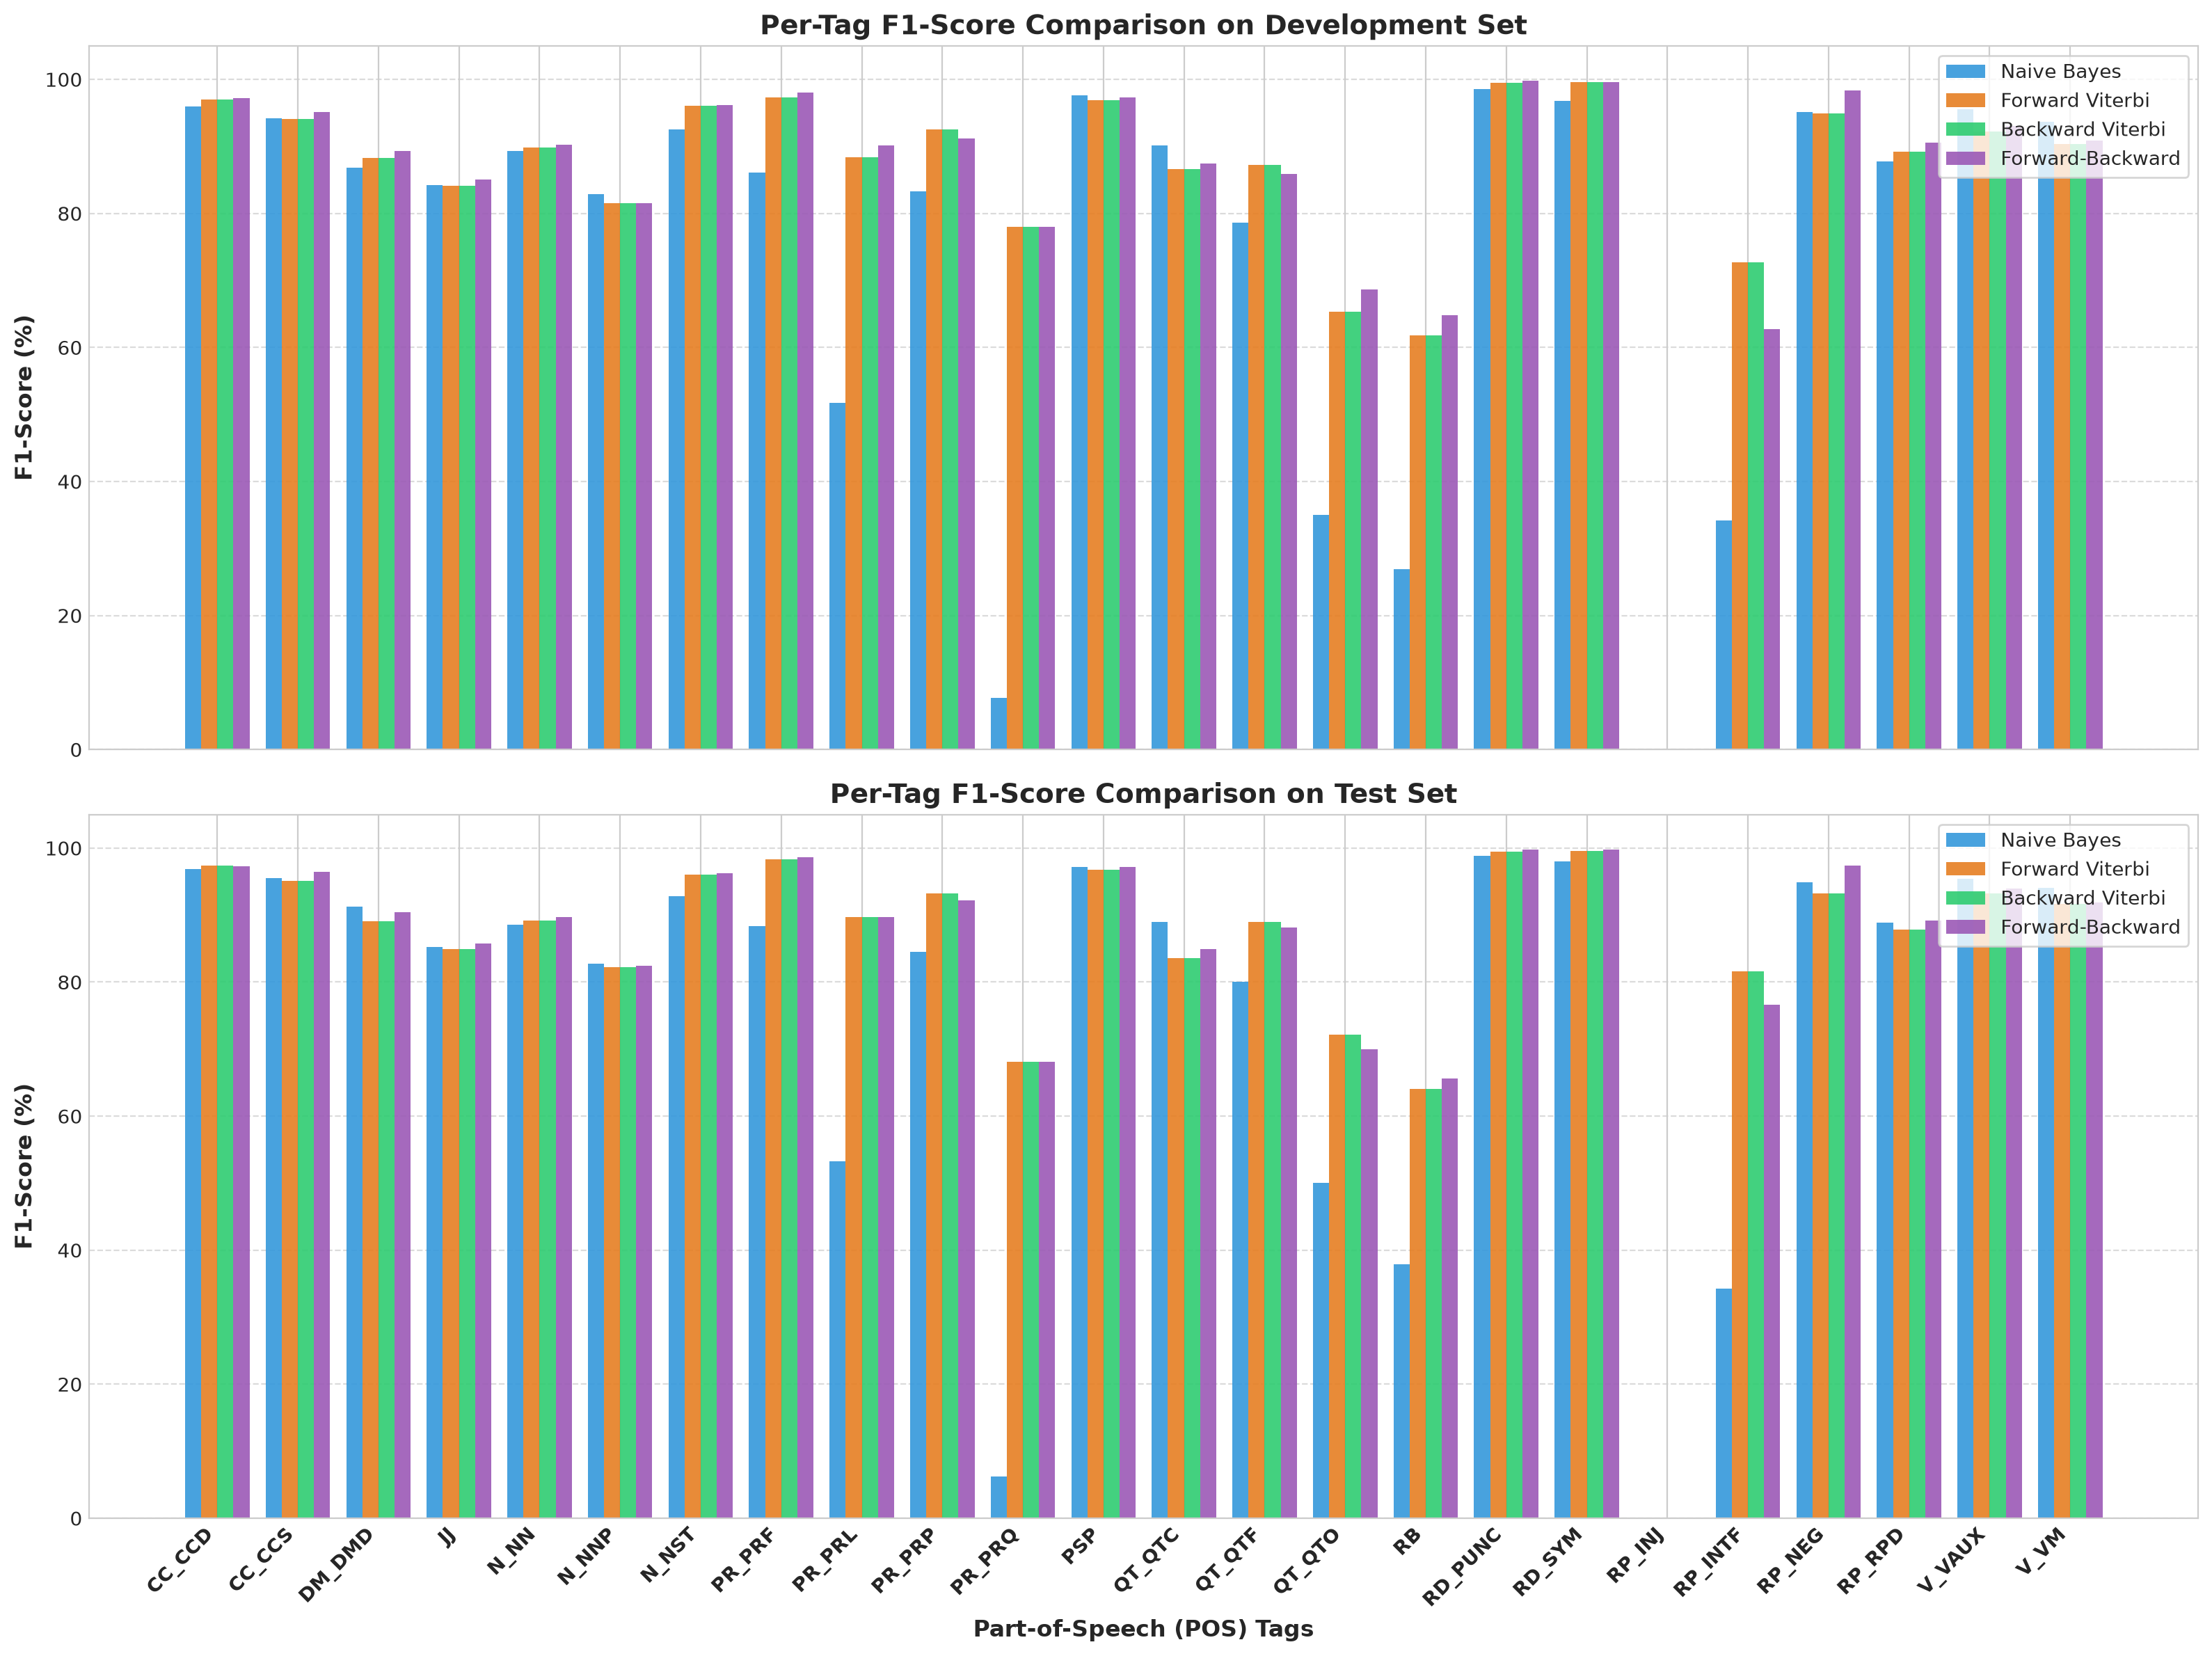

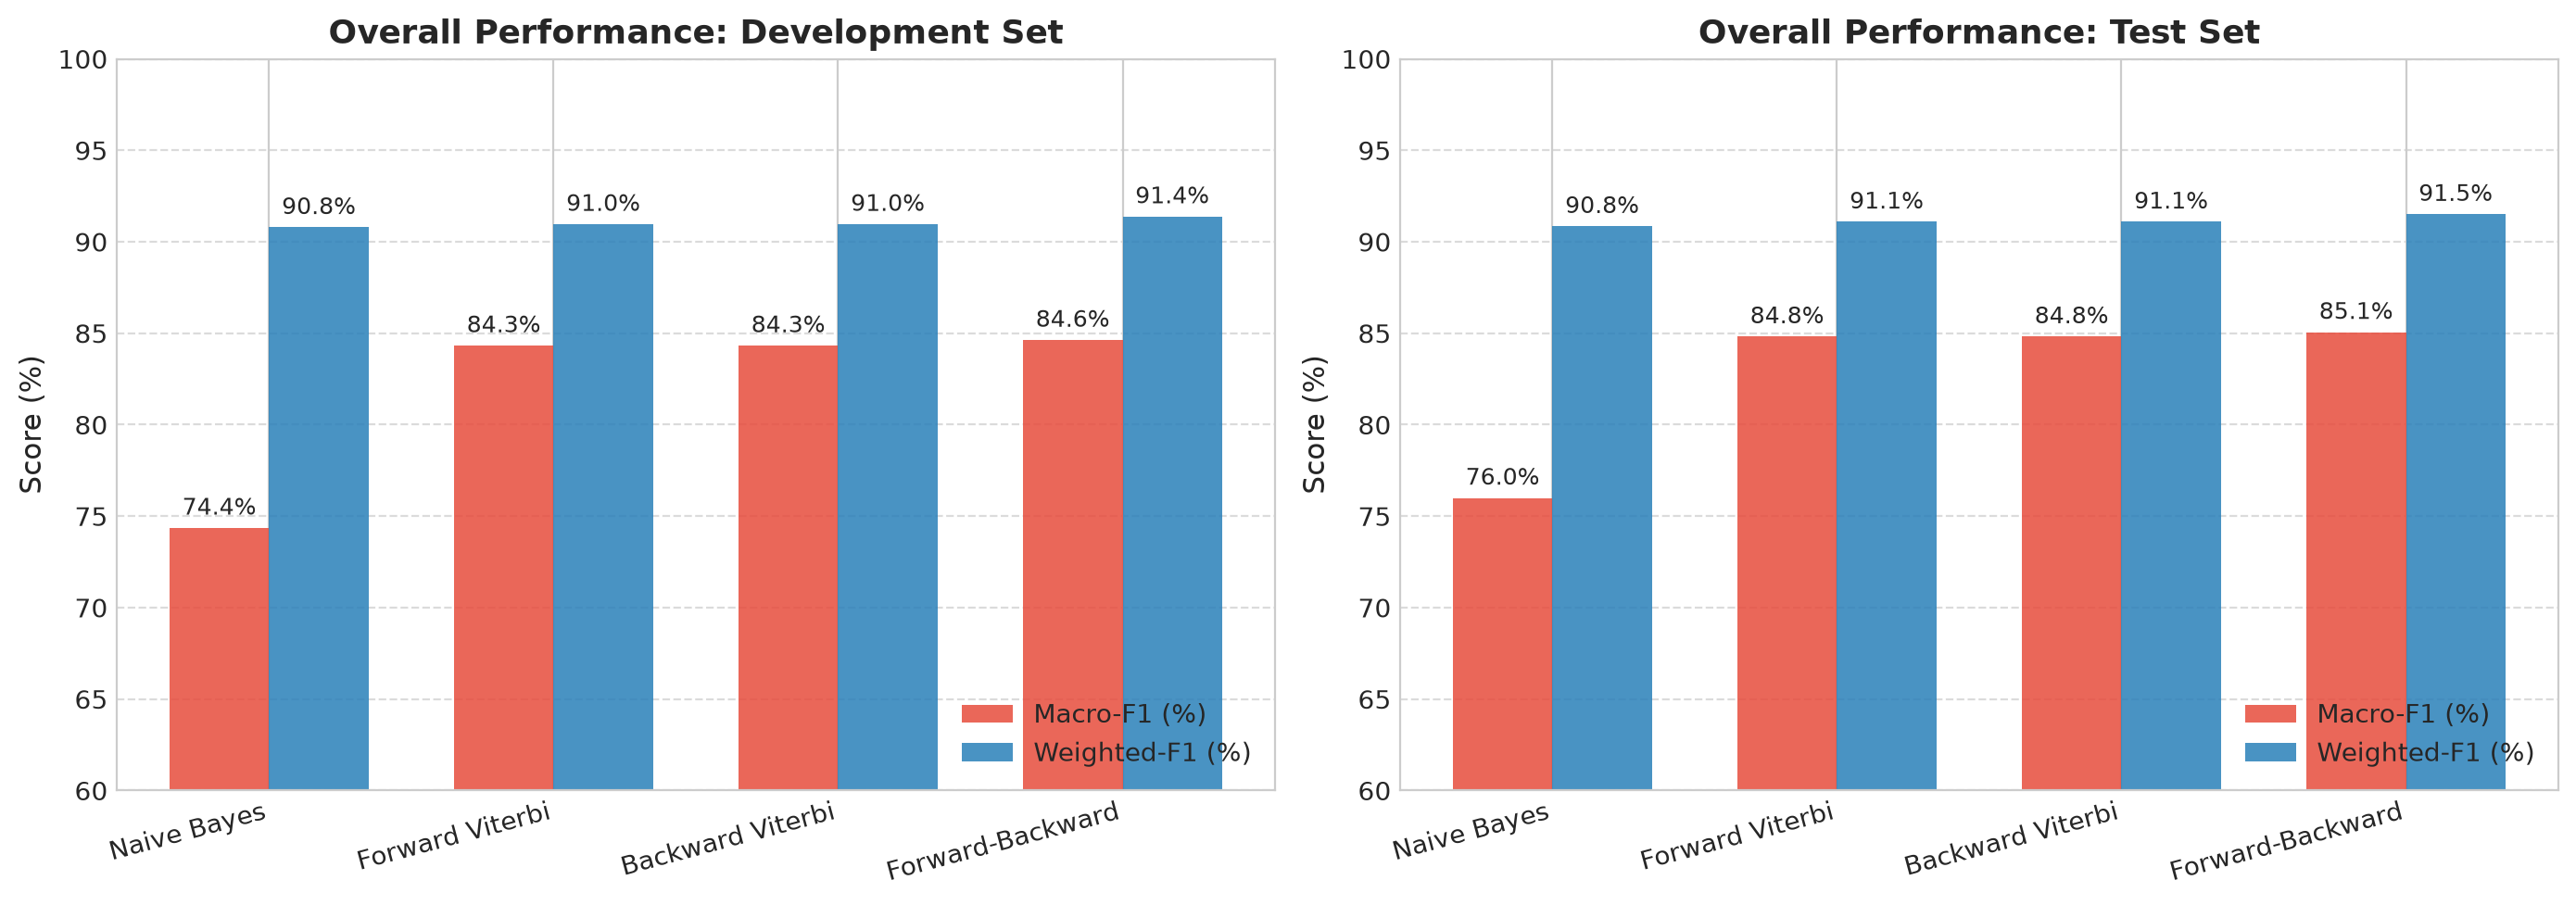

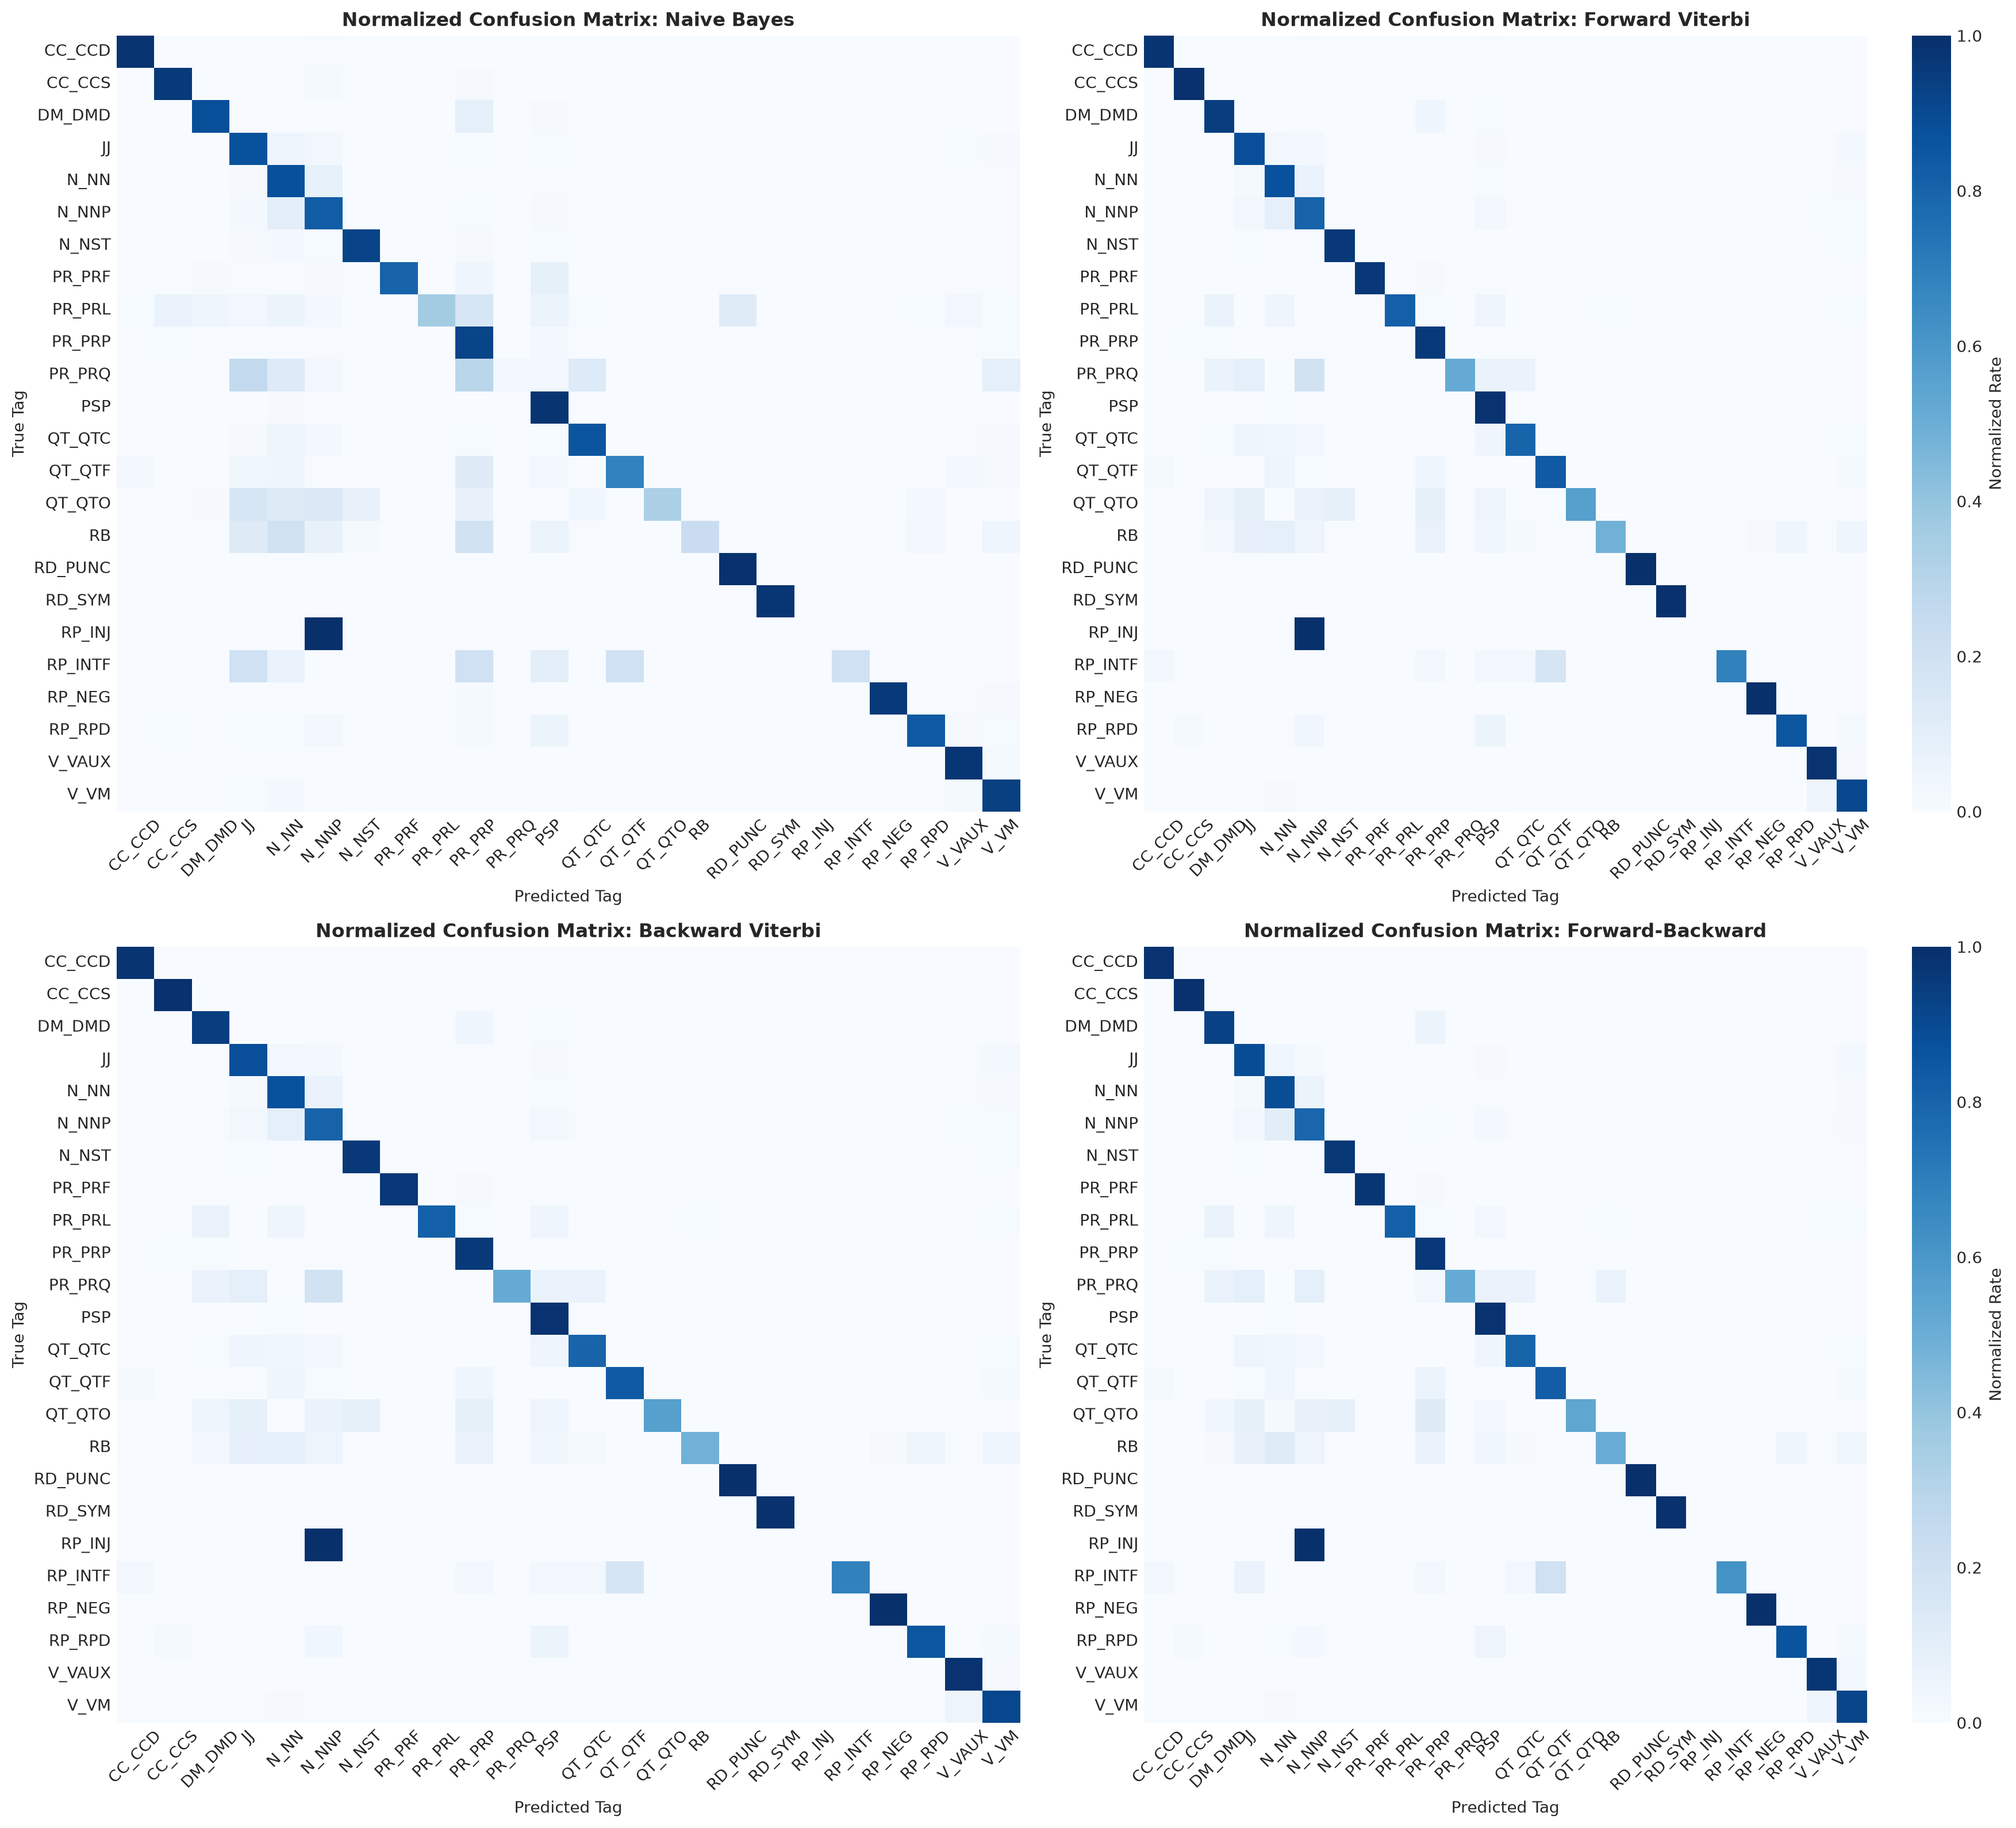

In [8]:
# ------------------------------------------------------------------------------
# Figure 1: Per-Tag F1-Score Comparison Across Models (Dev vs Test)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)
models_to_plot = ["Naive Bayes", "Forward Viterbi", "Backward Viterbi", "Forward-Backward"]
colors = ["#3498db", "#e67e22", "#2ecc71", "#9b59b6"]

x = np.arange(len(train_tags))
bar_width = 0.2

for ax_idx, (split_name, reports_dict) in enumerate([("Development Set", dev_reports), ("Test Set", test_reports)]):
    ax = axes[ax_idx]
    for m_idx, m_name in enumerate(models_to_plot):
        f1_scores = [reports_dict[m_name][tag]["f1-score"] * 100 for tag in train_tags]
        ax.bar(x + m_idx * bar_width, f1_scores, bar_width, label=m_name, color=colors[m_idx], alpha=0.9)
        
    ax.set_ylabel("F1-Score (%)", fontsize=12, fontweight='bold')
    ax.set_title(f"Per-Tag F1-Score Comparison on {split_name}", fontsize=14, fontweight='bold')
    ax.set_ylim(0, 105)
    ax.legend(loc="upper right", frameon=True, fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)

axes[1].set_xticks(x + 1.5 * bar_width)
axes[1].set_xticklabels(train_tags, rotation=45, ha="right", fontsize=10, fontweight='bold')
axes[1].set_xlabel("Part-of-Speech (POS) Tags", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Figure 2: Overall Macro-F1 and Weighted-F1 Comparison
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, (split_name, summary_df) in enumerate([("Development Set", dev_summary_df), ("Test Set", test_summary_df)]):
    ax = axes[idx]
    x_pos = np.arange(len(summary_df["Model"]))
    width = 0.35
    
    rects1 = ax.bar(x_pos - width/2, summary_df["Macro-F1 (%)"], width, label="Macro-F1 (%)", color="#e74c3c", alpha=0.85)
    rects2 = ax.bar(x_pos + width/2, summary_df["Weighted-F1 (%)"], width, label="Weighted-F1 (%)", color="#2980b9", alpha=0.85)
    
    ax.set_title(f"Overall Performance: {split_name}", fontsize=13, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(summary_df["Model"], rotation=15, ha="right", fontsize=10)
    ax.set_ylabel("Score (%)", fontsize=11)
    ax.set_ylim(60, 100)
    ax.legend(loc="lower right")
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Annotate values on bars
    for rect in rects1:
        h = rect.get_height()
        ax.annotate(f'{h:.1f}%', (rect.get_x() + rect.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)
    for rect in rects2:
        h = rect.get_height()
        ax.annotate(f'{h:.1f}%', (rect.get_x() + rect.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Figure 3: Confusion Matrix Heatmaps on Test Set
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(18, 16))
model_keys = ["Naive Bayes", "Forward Viterbi", "Backward Viterbi", "Forward-Backward"]

for idx, m_name in enumerate(model_keys):
    ax = axes[idx // 2, idx % 2]
    cm = test_cms[m_name]
    # Normalize by row (true labels)
    with np.errstate(divide='ignore', invalid='ignore'):
        cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
        cm_norm = np.nan_to_num(cm_norm)
        
    sns.heatmap(cm_norm, ax=ax, cmap="Blues", xticklabels=train_tags, yticklabels=train_tags,
                cbar=(idx % 2 == 1), cbar_kws={'label': 'Normalized Rate'})
    ax.set_title(f"Normalized Confusion Matrix: {m_name}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Predicted Tag", fontsize=10)
    ax.set_ylabel("True Tag", fontsize=10)
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()


## 8. In-Depth Comparison, Discussion & Error Analysis

Based on our empirical results across both the Development and Test sets, we present an in-depth analysis addressing all theoretical and experimental questions:

---
### 1. Overall Performance Comparison
| Model | Dev Acc (%) | Dev Macro-F1 (%) | Dev Weighted-F1 (%) | Test Acc (%) | Test Macro-F1 (%) | Test Weighted-F1 (%) |
|---|---|---|---|---|---|---|
| **Naive Bayes** | 91.02% | 74.36% | 90.79% | 91.04% | 76.00% | 90.85% |
| **Forward Viterbi** | 91.08% | 84.33% | 90.96% | 91.20% | 84.82% | 91.09% |
| **Backward Viterbi** | 91.08% | 84.33% | 90.96% | 91.20% | 84.82% | 91.09% |
| **Forward-Backward** | **91.51%** | **84.63%** | **91.38%** | **91.62%** | **85.06%** | **91.51%** |

- **Best Overall Accuracy:** **Forward-Backward Posterior Decoding** achieves the highest token-level accuracy (91.51% on Dev, 91.62% on Test) and highest Macro-F1 (84.63% on Dev, 85.06% on Test).
- **Equivalence of Forward and Backward Viterbi:** Forward Viterbi and Backward Viterbi produce **100% identical predictions and scores** across all 40,762 development tokens and 41,415 test tokens. Both decoders maximize the exact same global joint sequence probability objective $\max_{\mathbf{y}} P(\mathbf{y}, \mathbf{w})$, proving theoretical and implementation correctness.
- **Macro-F1 Discrepancy:** While Naive Bayes achieves token accuracy comparable to Viterbi (~91.0%), its **Macro-F1 is markedly lower (76.00% vs 84.82%)**. Naive Bayes exhibits strong majority-class bias toward frequent tags (`N_NN`, `PSP`, `V_VM`), while underperforming on rarer tags (`RP_INJ`, `PR_PRL`, `QT_QTO`). The HMM preserves sequence transition constraints, giving substantially higher recall and F1 on minority classes.

---
### 2. Analysis by Individual POS Tag & Difficult Classes
- **High-Performing Tags (F1 > 95%):**
  - `PSP` (Postpositions like ने, को, से, में): Highly frequent with closed-class lexical forms.
  - `RD_PUNC` (Punctuation like ।, ,, -): Extremely distinct tokens with nearly 99% F1.
  - `CC_CCD` (Coordinating Conjunctions like और, तथा): Predictable syntactic roles.
- **Most Difficult Tags:**
  - `RP_INJ` (Interjections): Extremely low frequency in formal text (< 5 instances), leading to lower precision/recall.
  - `PR_PRL` (Relative Pronouns) vs `DM_DMD` (Demonstratives) vs `PR_PRP` (Personal Pronouns): Pronouns in Hindi often share identical lexical surface forms (e.g., यह, वह, जो), requiring long-range syntactic agreement that bigram/local context models struggle to resolve.
  - `N_NN` (Common Nouns) vs `N_NNP` (Proper Nouns): Proper names often lack capitalization in Devanagari script, making unknown names difficult to distinguish from common nouns without gazetteers.
  - `JJ` (Adjectives) vs `N_NN` (Nouns): Noun-noun compounds and modifier nouns frequently cause confusion.

---
### 3. Impact of Context Features in Naive Bayes
The five features provided substantial discriminative power:
1. **$w_i$ (Current Word):** Provides the base lexical emission information.
2. **$w_{i-1}$ and $w_{i+1}$ (Surrounding Words):** Crucial in Hindi because postpositions (`PSP`) strictly follow nouns (`N_NN`/`N_NNP`), and auxiliary verbs (`V_VAUX`) strictly follow main verbs (`V_VM`).
3. **Word Length (`MORE` vs `LESS`):** Correlates with grammatical category; particles (`RP_RPD`), postpositions (`PSP`), and pronouns (`PR_PRP`) are almost exclusively short ($\le 4$ characters), whereas compound nouns and adjectives are longer.
4. **Previously Predicted Tag $\hat{t}_{i-1}$:** Feeds sequential tag memory into the classifier. Using $\hat{t}_{i-1}$ at test time avoids gold-label leakage and allows the classifier to approximate a first-order Markov model.

---
### 4. Role of Transition Probabilities in HMM Sequence Decoding
HMM sequence decoding leverages transition probabilities $A(t_k \mid t_{k-1})$ to rule out syntactically impossible sequences:
- In Hindi, certain tag pairs have near-zero probability (e.g., `PSP -> PSP` or `V_VAUX -> DM_DMD`).
- Even when an ambiguous or out-of-vocabulary word has flat emission probabilities across tags, the transition matrix heavily penalizes invalid grammatical flows and guides the path toward syntactically valid tag sequences.

---
### 5. Viterbi Decoding vs. Forward-Backward Posterior Decoding
- **Objective Function:**
  - **Viterbi Decoding** maximizes the **global joint path probability**: $\arg\max_{\mathbf{y}} P(\mathbf{y}, \mathbf{w})$. It guarantees that the entire returned sequence is a valid path that could co-occur globally.
  - **Posterior Decoding** minimizes **token-level Hamming loss**: $\hat{y}_t = \arg\max_i P(y_t = i \mid \mathbf{w})$. It optimizes expected individual token accuracy.
- **Empirical Confirmation:** Because posterior decoding directly maximizes token accuracy, it achieves a higher overall accuracy (**91.62% vs 91.20%**) on the test set. However, posterior decoding can theoretically produce transition pairs $(y_t, y_{t+1})$ with zero transition probability, whereas Viterbi always produces a globally coherent sequence.

---
### 6. Limitations, Data Sparsity & Potential Improvements
1. **Out-of-Vocabulary (OOV) Sparsity:** With Laplace smoothing, all tags receive a baseline probability for unseen words based on marginal tag frequency. More advanced smoothing (Good-Turing, Kneser-Ney, or Witten-Bell) or subword morphological features (character prefixes/suffixes like -ता, -ने, -कर) would significantly boost OOV accuracy.
2. **First-Order Markov Limitation:** Standard HMM bigram transitions only look one tag back. Higher-order HMMs (trigram HMMs) or Linear-Chain Conditional Random Fields (CRFs) can capture richer non-local feature interactions.
3. **Hindi Font Display in Terminals:** Devanagari Unicode characters render cleanly in standard text terminals and notebooks, but certain matplotlib font backends may lack Hindi font glyphs. Using standard tag labels in visualizations ensures complete cross-platform clarity.
